# Regional Ravat-style L2resL1 inversion with GravMagSphere

This runnable pipeline uses the native GravMagSphere equivalent-monopole kernel, a robust L2 baseline, and an L1-regularized residual correction. It follows the objective structure in [Ravat et al. (2020), sections 2 and 5.1](https://doi.org/10.1029/2019JE006187). It is a **method replica**, not a claim to reproduce the exact published inversion.

Default inputs are the user-selected MoonBroom filtered wake products, using undetrended 90th-percentile Brms files below 40 km. The time window is January 1–July 28, 1999; observations are cropped to the configured regional bounds. Set `DEMO=True` for the synthetic experiment. The MoonBroom selection is not asserted identical to the paper’s selection. The published surface DAT/COF files are comparison products, not orbital inversion inputs. No downloads are made. See `docs/ravat.md` for equations, error covariance, source placement, tuning and limitations.

**Current preprocessing:** Ravat-style five-second along-track differences of **Br, Btheta and Bphi**, with no polynomial detrending or ad-hoc pass corrections. Fit differences only; absolute vectors remain available for diagnostic comparison. Every valid consecutive pair is retained, with full covariance for shared endpoints. January–July 1999 and the existing MoonBroom wake cuts are recorded. Data discarded by the upstream <40 km / Brms filter cannot be recovered here. The original paper's fitted internal/external dipole coefficients are unavailable and have not been reconstructed. This is a documented methodological approximation, not an exact recreation of the original preprocessing.


In [1]:
from pathlib import Path
import sys
import runpy
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/gravmagpy').is_dir())
sys.path.insert(0, str(ROOT/'src'))
from gravmagpy import (load_lpmag_csv, along_track_differences, regional_monopole_grid,
    fit_ravat_l2resl1, predict_ravat_field, save_ravat_fit)
from gravmagpy.ravat import ellipsoid_points, load_moonbroom_wake


## Configuration and input contract

Real CSVs must contain `utc`, `X_SEL/Y_SEL/Z_SEL` in km, and `Bx_SEL/By_SEL/Bz_SEL` in nT in a body-fixed frame. Use the Python loader's mapping options for other columns. For custom CSVs, apply the intended selection upstream and set `SELECTION_CONFIRMED=True`. The default MoonBroom branch uses the existing filtered wake files and records their selection separately; it does not assert equivalence to the paper’s selection. Use a padded regional subset of orbital data; the source bounds do not crop the input files.

The demonstration uses 15 km source spacing / 10 km radial depth, not an asserted exact Reiner Gamma geometry. Both the paper's 7 km / 5 km text values and 8.7 km / 10 km Figure 5 caption values can be tested. Alphas are examples for this normalization and must be selected for each real dataset, using withheld passes and surface stability.

In [2]:
DEMO = False
DATA_MODE = "differences"
PAIRING = "adjacent" if DATA_MODE == "differences" else "disjoint"
WAKE_DIR = Path("/Users/danywaller/Projects/moon/lpmag_l1b_5s_avg/lp_mag_nightside_filtering/filtered_wake")
USE_MOONBROOM_WAKE = True
OBSERVATION_FILES = []  # Paths to selected regional orbital CSVs, not surface DAT files.
SELECTION_CONFIRMED = False
BOUNDS = (299., 4., 305., 11.)  # west, south, east, north; degrees E/N
SPACING_KM, DEPTH_KM = 15., 10.
ALPHA_L2, ALPHA_L1 = 0.2, 2.0
EPSILON_NT, SIGMA_NT = 0.1, 1.0  # Assumed component uncertainty; Brms is not measurement sigma.
MAX_ITERATIONS, MEMORY_MIB = 1000, 512
OUTPUT = ROOT/('examples/ravat_l2resl1/output' if DEMO else 'examples/ravat_l2resl1/output/filtered_wake')
if not DEMO:
    OUTPUT = OUTPUT/DATA_MODE
OUTPUT.mkdir(parents=True, exist_ok=True)


In [3]:
if DEMO:
    helper = runpy.run_path(str(ROOT/'examples/ravat_l2resl1/run.py'))
    observations = helper['synthetic_observations']()
elif USE_MOONBROOM_WAKE:
    observations = load_moonbroom_wake(WAKE_DIR, bounds=BOUNDS, sigma_nt=SIGMA_NT)
    display(observations['selection'])
else:
    if not SELECTION_CONFIRMED or not OBSERVATION_FILES:
        raise ValueError('Provide selected orbital CSV paths and confirm upstream paper-style selection.')
    observations = load_lpmag_csv(OBSERVATION_FILES, wake_only=False,
        sigma_nt=SIGMA_NT, altitude_range_km=(12,48))
differences = along_track_differences(observations, cadence_s=5, tolerance_s=0.6, pairing=PAIRING)
source_grid = regional_monopole_grid(BOUNDS, spacing_km=SPACING_KM, depth_km=DEPTH_KM)
print('Mode:', 'SYNTHETIC DEMONSTRATION' if DEMO else 'selected orbital data')
print('Orbital samples:', len(observations['xyz_km']))
print('Five-second along-track difference pairs:', len(differences['pairs']))
print('Equivalent monopoles:', len(source_grid['source_xyz_km']))

display(differences['preprocessing'])
display(differences['pair_table'].head())
print('No polynomial detrending, per-pass vector subtraction, or ad-hoc rejection is applied here.')


{'directory': '/Users/danywaller/Projects/moon/lpmag_l1b_5s_avg/lp_mag_nightside_filtering/filtered_wake/alt_lt_40km_brms_90pct', 'pattern': 'ma*_nightside_wake_alt_lt_40km_brms_90pct.csv', 'start_inclusive': '1999-01-01T00:00:00+00:00', 'stop_exclusive': '1999-07-29T00:00:00+00:00', 'bounds': [299.0, 4.0, 305.0, 11.0], 'input_products': 'undetrended filtered wake: alt_lt_40km_brms_90pct', 'additional_radial_altitude_km': [12, 40], 'radial_reference_km': 1737.4, 'sigma_nt': 1.0, 'sigma_is_assumed': True, 'caveat': "MoonBroom selection; equivalence to the paper's wake/tail/quality selection has not been established"}
Mode: selected orbital data
Orbital samples: 550
Five-second along-track difference pairs: 443
Equivalent monopoles: 190
{'pairing': 'adjacent', 'cadence_s': 5, 'tolerance_s': 0.6, 'components': ['Br', 'Btheta', 'Bphi'], 'difference_sign': 'later minus earlier', 'units': 'nT per finite five-second interval; not divided by separation or time', 'detrending': 'none', 'ad_hoc_p

## Gradient-based preprocessing check

Inspect one uninterrupted track segment: the input Br/Btheta/Bphi values on the left and their **five-second finite differences** on the right. No polynomial or per-pass trend has been fitted or removed. Both endpoints are in the same file and contiguous original rows with valid timing. The full run uses every valid pair; gaps start new covariance blocks. Differences are later minus earlier, in nT, without division by separation or elapsed time.

  component  number_of_differences  mean_difference_nT  rms_difference_nT
0        Br                    443           -0.108511           1.616636
1    Btheta                    443            0.027088           1.476679
2      Bphi                    443           -0.005841           1.369626
Elapsed-time range (s): 5.0 5.0
Separation range (km): 8.282680725465669 8.407966460446918


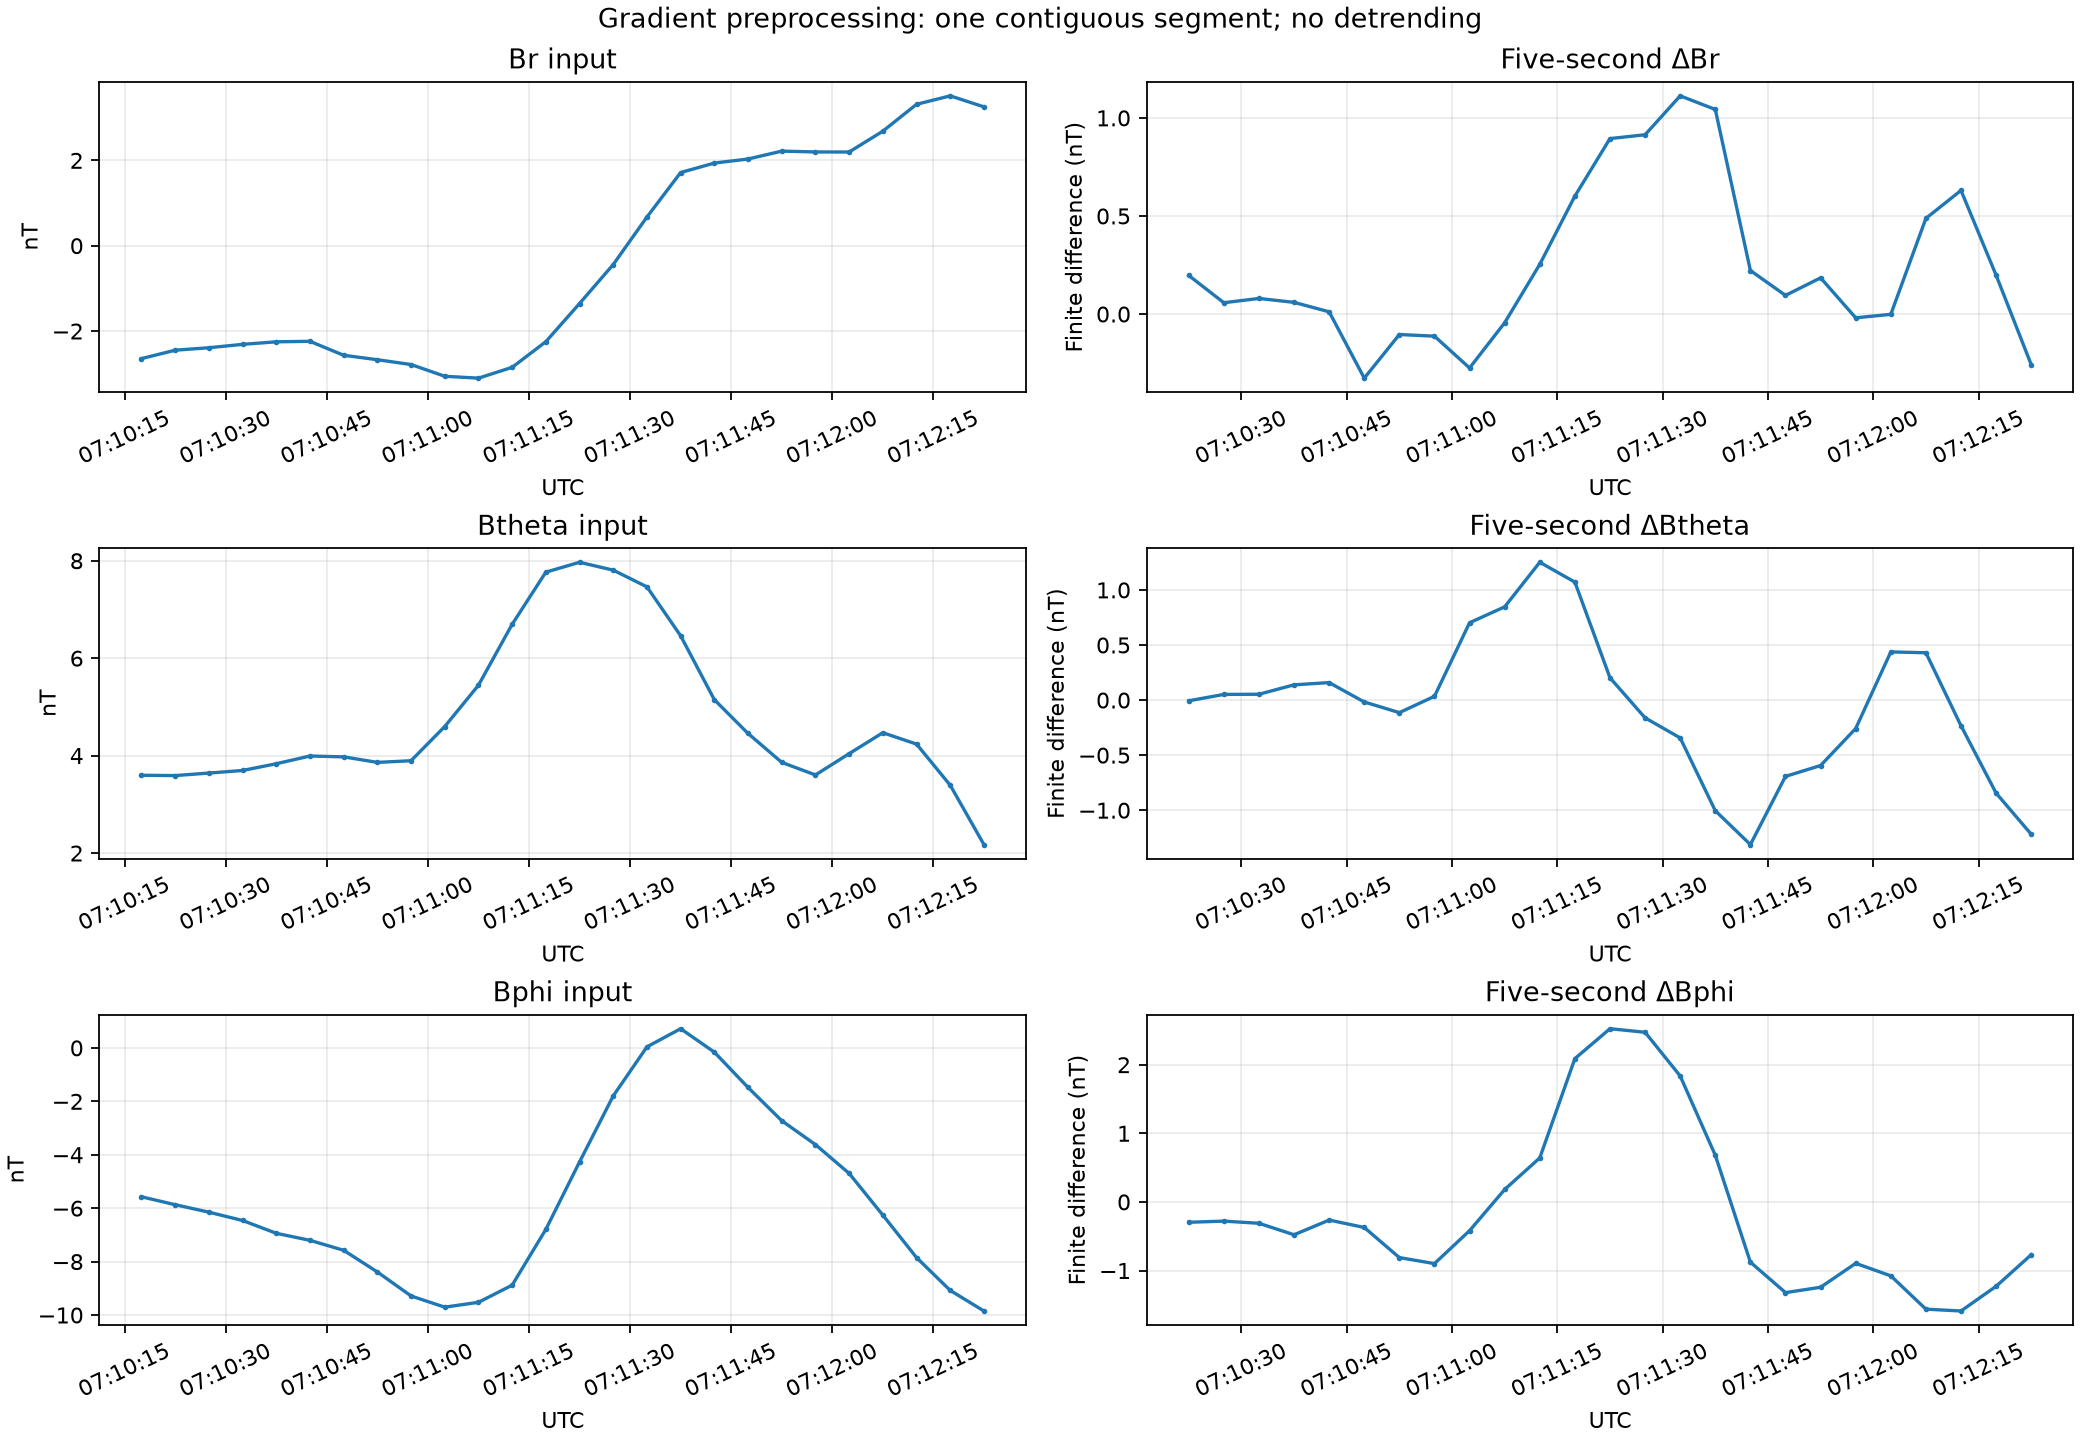

In [4]:
pair_audit = differences['pair_table']
new_segment = (pair_audit.source_file != pair_audit.source_file.shift()) | (pair_audit.left_index != pair_audit.right_index.shift())
segment_labels = new_segment.cumsum()
segment = segment_labels.value_counts().idxmax()
segment_rows = np.flatnonzero(segment_labels.to_numpy() == segment)
selected_pairs = differences['pairs'][segment_rows]
selected_samples = np.r_[selected_pairs[0,0], selected_pairs[:,1]]
input_times = pd.to_datetime(observations['table'].utc.iloc[selected_samples], utc=True)
difference_times = pd.to_datetime(pair_audit.right_utc.iloc[segment_rows], utc=True)
fig, axes = plt.subplots(3,2,figsize=(13,9),constrained_layout=True)
for j, component in enumerate(['Br','Btheta','Bphi']):
    axes[j,0].plot(input_times, differences['vector_nt'][selected_samples,j], '.-', ms=3)
    axes[j,0].set(title=component+' input',ylabel='nT')
    axes[j,1].plot(difference_times, differences['difference_nt'][segment_rows,j], '.-', ms=3)
    axes[j,1].set(title='Five-second Δ'+component,ylabel='Finite difference (nT)')
    for ax in axes[j]:
        ax.set_xlabel('UTC')
        ax.grid(alpha=0.25)
        ax.tick_params(axis='x',rotation=25)
fig.suptitle('Gradient preprocessing: one contiguous segment; no detrending')
fig.savefig(OUTPUT/'gradient_preprocessing.png',dpi=160)
plt.show()
gradient_audit = pd.DataFrame(dict(component=['Br','Btheta','Bphi'],
    number_of_differences=len(pair_audit),
    mean_difference_nT=differences['difference_nt'].mean(axis=0),
    rms_difference_nT=np.sqrt(np.mean(differences['difference_nt']**2,axis=0))))
display(gradient_audit)
print('Elapsed-time range (s):', pair_audit.dt_s.min(), pair_audit.dt_s.max())
print('Separation range (km):', pair_audit.separation_km.min(), pair_audit.separation_km.max())
gradient_audit.to_csv(OUTPUT/'gradient_preprocessing_summary.csv',index=False)


## Fit the two stages to all component differences

L2 penalizes mean squared baseline surface Br; residual L1 penalizes the smooth absolute surface Br of the correction. **Delta Br, Delta Btheta and Delta Bphi all enter the data objective**. Raw vectors and magnitudes are not fitted in the default differences-only mode.

Rotate each endpoint into its own spherical basis, then take `later − earlier` for every valid five-second pair. These differences remain in nT; do not divide them by time or distance. Reject file, original-row, pass and time gaps. No polynomial or arbitrary per-orbit baseline is removed.

Covariance between neighboring differences is **minus the covariance of their shared endpoint**. A block-Cholesky whitening accounts for that covariance without constructing a dense full-track matrix. Tukey c=4.5 weights whitened residuals. Shared-endpoint covariance propagation is an explicit implementation choice; the paper describes variance weights but does not specify this exact whitening procedure. Convergence checks the objective and predicted/regularized fields.

Converged: True | L2: True | residual L1: True
Mode: differences | Independent whitened rows: 1329
Vector RMSE (nT): 5.6179677008732245
Difference RMSE (nT): 1.083208827352656
    iteration    objective  relative_change  ...  active_rows  rank  stalled
16         17  1000.289168         0.000225  ...         1300   190    False
17         18  1000.289166         0.000095  ...         1300   190    False
18         19  1000.289165         0.000041  ...         1300   190    False
19         20  1000.289165         0.000018  ...         1300   190    False
20         21  1000.289165         0.000008  ...         1300   190    False

[5 rows x 8 columns]      iteration   objective  relative_change  ...  active_rows  rank  stalled
157        158  938.625432         0.000015  ...         1300   190    False
158        159  938.625432         0.000014  ...         1300   190    False
159        160  938.625432         0.000013  ...         1300   190    False
160        161  938.625432      

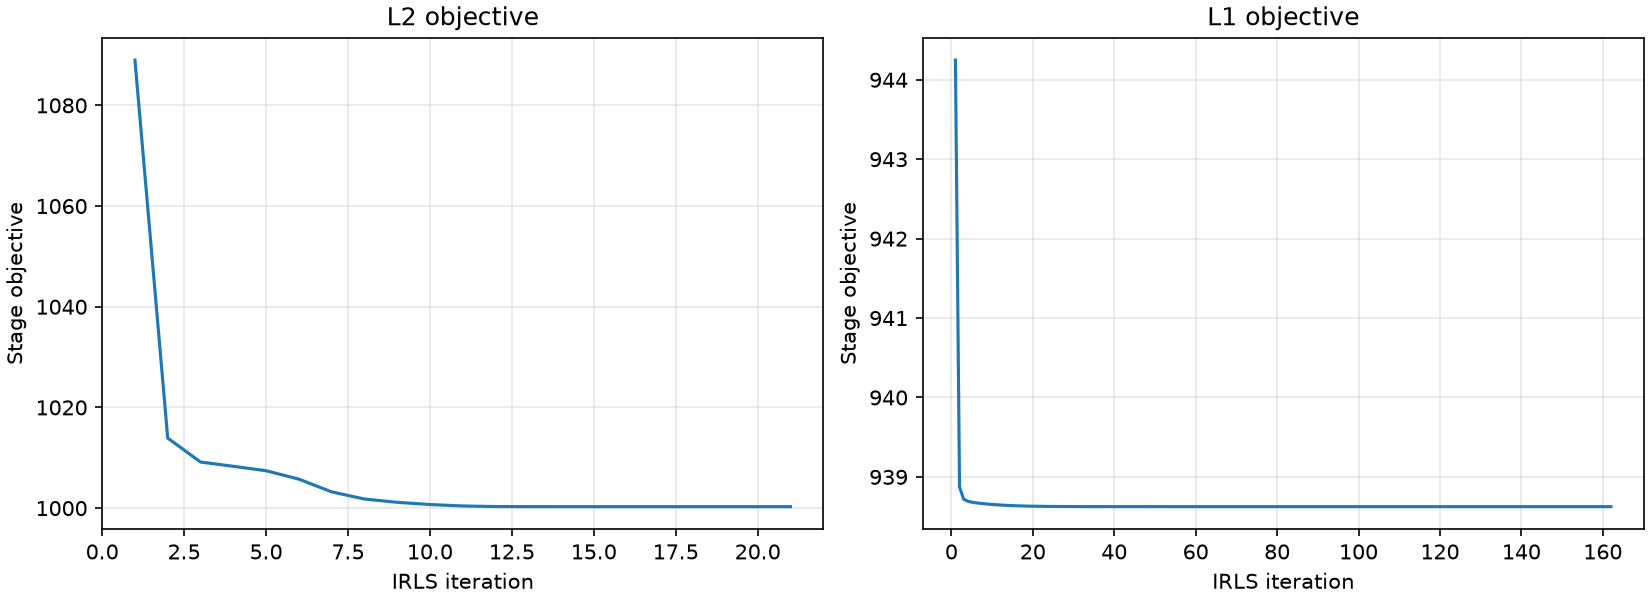

In [5]:
fit = fit_ravat_l2resl1(differences, source_grid['source_xyz_km'],
    source_grid['surface_xyz_km'], area_weights=source_grid['area_weights'],
    alpha_l2=ALPHA_L2, alpha_l1=ALPHA_L1, epsilon_nt=EPSILON_NT,
    max_iterations=MAX_ITERATIONS, max_memory_mib=MEMORY_MIB, data_mode=DATA_MODE)
print('Converged:', fit['success'], '| L2:', fit['converged_l2'], '| residual L1:', fit['converged_l1'])
print('Mode:', fit['data_mode'], '| Independent whitened rows:', fit['independent_data_rows'])
print('Vector RMSE (nT):', np.sqrt(np.mean(fit['residual_vector_nt']**2)))
print('Difference RMSE (nT):', np.sqrt(np.mean(fit['residual_difference_nt']**2)))
display(fit['history_l2'].tail(), fit['history_l1'].tail())
fig, axes = plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
for ax, stage in zip(axes, ['l2','l1']):
    history = fit['history_'+stage]
    ax.plot(history.iteration, history.objective)
    ax.set(title=stage.upper()+' objective', xlabel='IRLS iteration', ylabel='Stage objective')
    ax.grid(alpha=0.3)
fig.savefig(OUTPUT/'irls_histories.png', dpi=150)
plt.show()


In [6]:
save_ravat_fit(fit, differences, OUTPUT)
observations['table'].to_csv(OUTPUT/'observation_index.csv', index=False)
source_grid['table'].to_csv(OUTPUT/'source_grid.csv', index=False)
config = dict(data_mode=DATA_MODE, preprocessing=differences['preprocessing'], wake_dir=str(WAKE_DIR), selection=observations.get('selection'), mode='synthetic demonstration' if DEMO else 'selected orbital data',
    observation_files=list(map(str, OBSERVATION_FILES)), bounds=BOUNDS,
    spacing_km=SPACING_KM, depth_km=DEPTH_KM, alpha_l2=ALPHA_L2, alpha_l1=ALPHA_L1,
    epsilon_nt=EPSILON_NT, sigma_nt=SIGMA_NT, max_iterations=MAX_ITERATIONS,
    memory_mib=MEMORY_MIB, selection_confirmed=SELECTION_CONFIRMED)
config['input_sha256'] = {str(p):hashlib.sha256(p.read_bytes()).hexdigest() for p in map(Path, observations['table'].source_file.unique())} if not DEMO else {}
(OUTPUT/'notebook_config.json').write_text(json.dumps(config,indent=2)+'\n')

if DEMO:
    validation = helper['validate_synthetic'](fit)
    display(validation)
    (OUTPUT/'synthetic_validation.json').write_text(json.dumps(validation,indent=2)+'\n')

pd.DataFrame(observations.get('report', [])).to_csv(OUTPUT/'input_report.csv', index=False)


## Surface maps of the baseline, correction and vector sum

All stages are evaluated on the 1738.1 × 1736.0 km ellipsoid. Compute the final magnitude **after adding vectors**: `norm(B_L2 + B_correction)`. Do not add the two stage magnitudes. These are synthetic maps in default mode; they are not the published regional L2resL1 model. A regional map can have edge artifacts; use a smaller interior interpretation window and test source padding.

The held-out synthetic diagnostics report both difference error and absolute-vector error. A low gradient misfit does not establish an accurate absolute field or a unique downward continuation: compare both, and do not interpret this demonstration as a validated reconstruction of the truth.

Saved fit, histories, map stages and configuration to /Users/danywaller/code/GravMagPy/examples/ravat_l2resl1/output/filtered_wake/differences


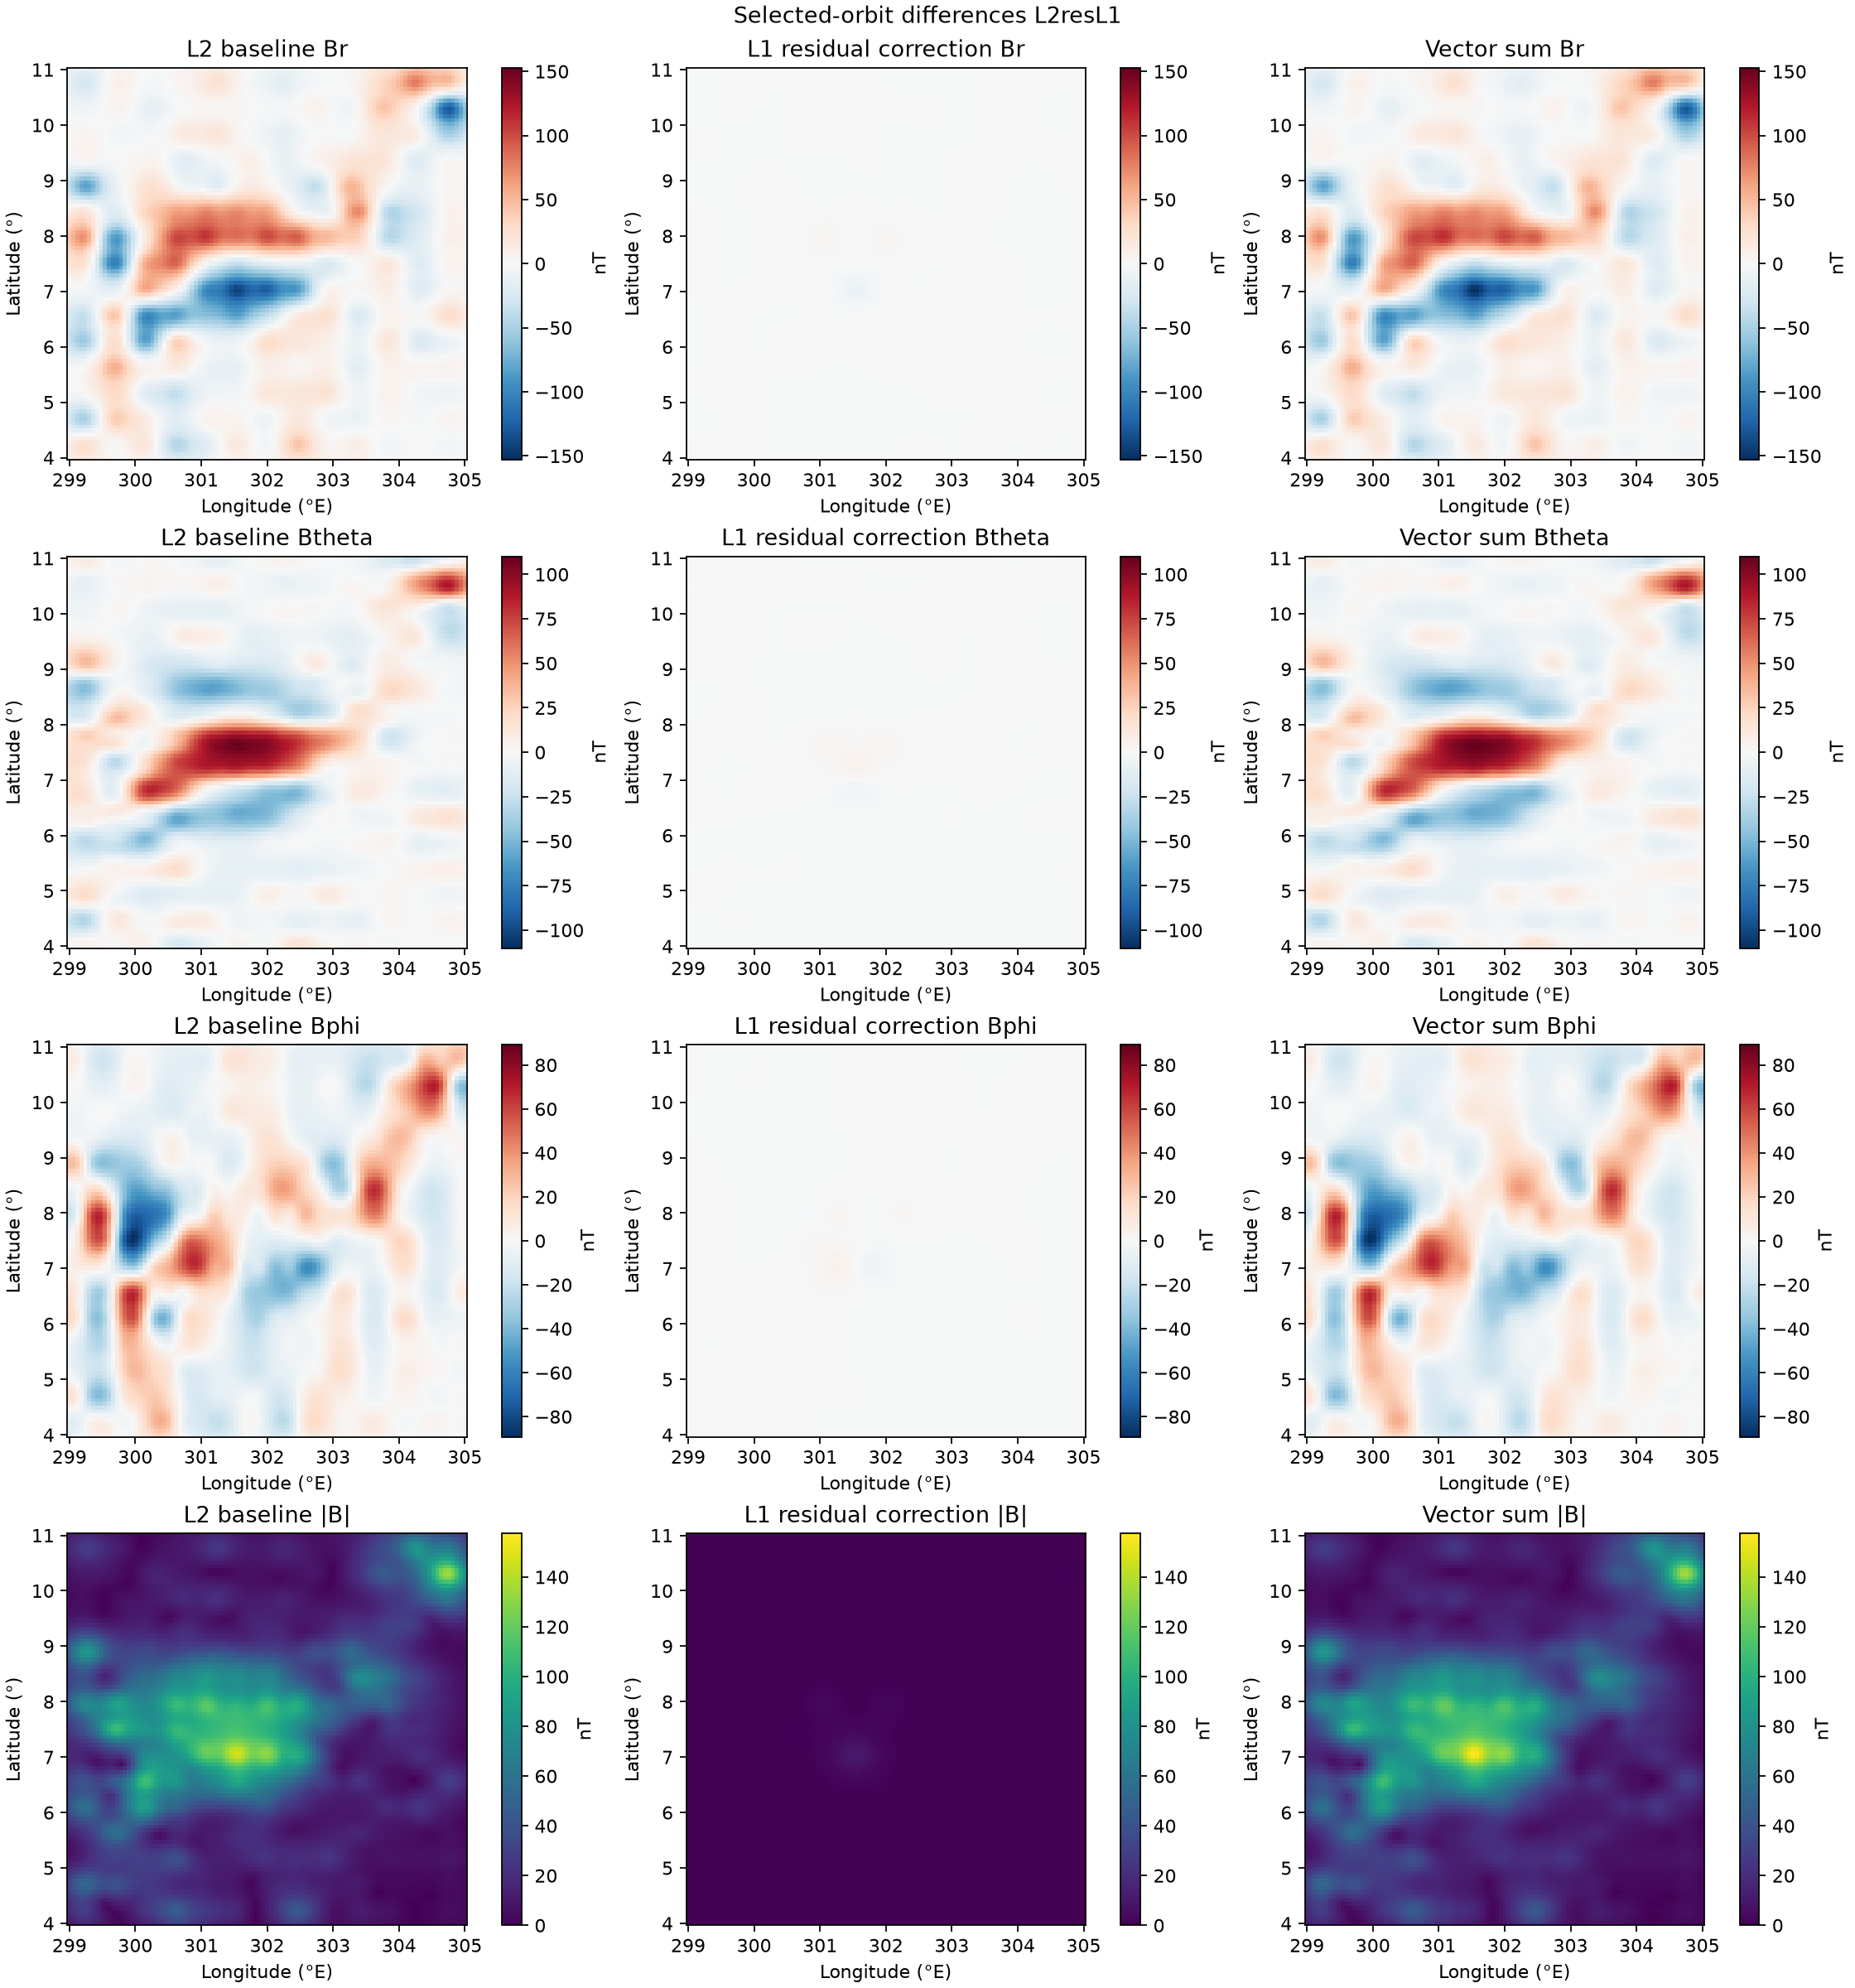

In [7]:
west, south, east, north = BOUNDS
if east < west:
    east += 360
lon, lat = np.meshgrid(np.linspace(west,east,101), np.linspace(south,north,101))
map_xyz = ellipsoid_points(lat.ravel(), lon.ravel())
stage_fields = {stage: predict_ravat_field(map_xyz, fit, part=stage)
                for stage in ['baseline','correction','total']}
np.testing.assert_allclose(stage_fields['total']['xyz_nt'],
    stage_fields['baseline']['xyz_nt']+stage_fields['correction']['xyz_nt'], atol=1e-10)
np.testing.assert_allclose(stage_fields['total']['total_nt'],
    np.linalg.norm(stage_fields['total']['rtp_nt'],axis=1), atol=1e-10)
fig, axes = plt.subplots(4,3,figsize=(14,15),constrained_layout=True)
for row, component in enumerate(['Br','Btheta','Bphi','|B|']):
    values = [stage_fields[stage]['rtp_nt'][:,row] if row < 3 else stage_fields[stage]['total_nt']
              for stage in ['baseline','correction','total']]
    limit = max(max(np.max(np.abs(value)) for value in values), 1e-12)
    for ax, title, value in zip(axes[row], ['L2 baseline','L1 residual correction','Vector sum'], values):
        im = ax.pcolormesh(lon,lat,value.reshape(lon.shape),shading='auto',
            cmap='RdBu_r' if row < 3 else 'viridis',vmin=-limit if row < 3 else 0,vmax=limit)
        ax.set(title=title+' '+component,xlabel='Longitude (°E)',ylabel='Latitude (°)')
        fig.colorbar(im,ax=ax,label='nT')
fig.suptitle(('Synthetic ' if DEMO else 'Selected-orbit ')+DATA_MODE+' L2resL1')
fig.savefig(OUTPUT/'surface_stages.png',dpi=160)
plt.show()
surface = pd.DataFrame({'lon_deg':lon.ravel(),'lat_deg':lat.ravel()})
for stage, values in stage_fields.items():
    for j, component in enumerate(['br','btheta','bphi']):
        surface[f'{stage}_{component}_nt'] = values['rtp_nt'][:,j]
    surface[f'{stage}_magnitude_nt'] = values['total_nt']
surface.to_csv(OUTPUT/'surface_field.csv.gz',index=False)
print('Saved fit, histories, map stages and configuration to', OUTPUT)


## Component-wise vector and along-track difference diagnostics
Residuals are predicted minus observed at the actual orbital positions. All three components share one fitted equivalent-source model. These are in-sample diagnostics, not withheld-pass validation. In differences-only mode, the absolute-vector row is diagnostic and is not part of the objective. Observed magnitudes are not additional fitted rows.

         data component   bias_nT   rmse_nT
0      Vector        Br -0.107580  4.609764
1      Vector    Btheta  0.167207  6.182462
2      Vector      Bphi  3.436900  5.933964
3  Difference        Br -0.013016  0.805401
4  Difference    Btheta -0.053620  1.156683
5  Difference      Bphi -0.047465  1.238320


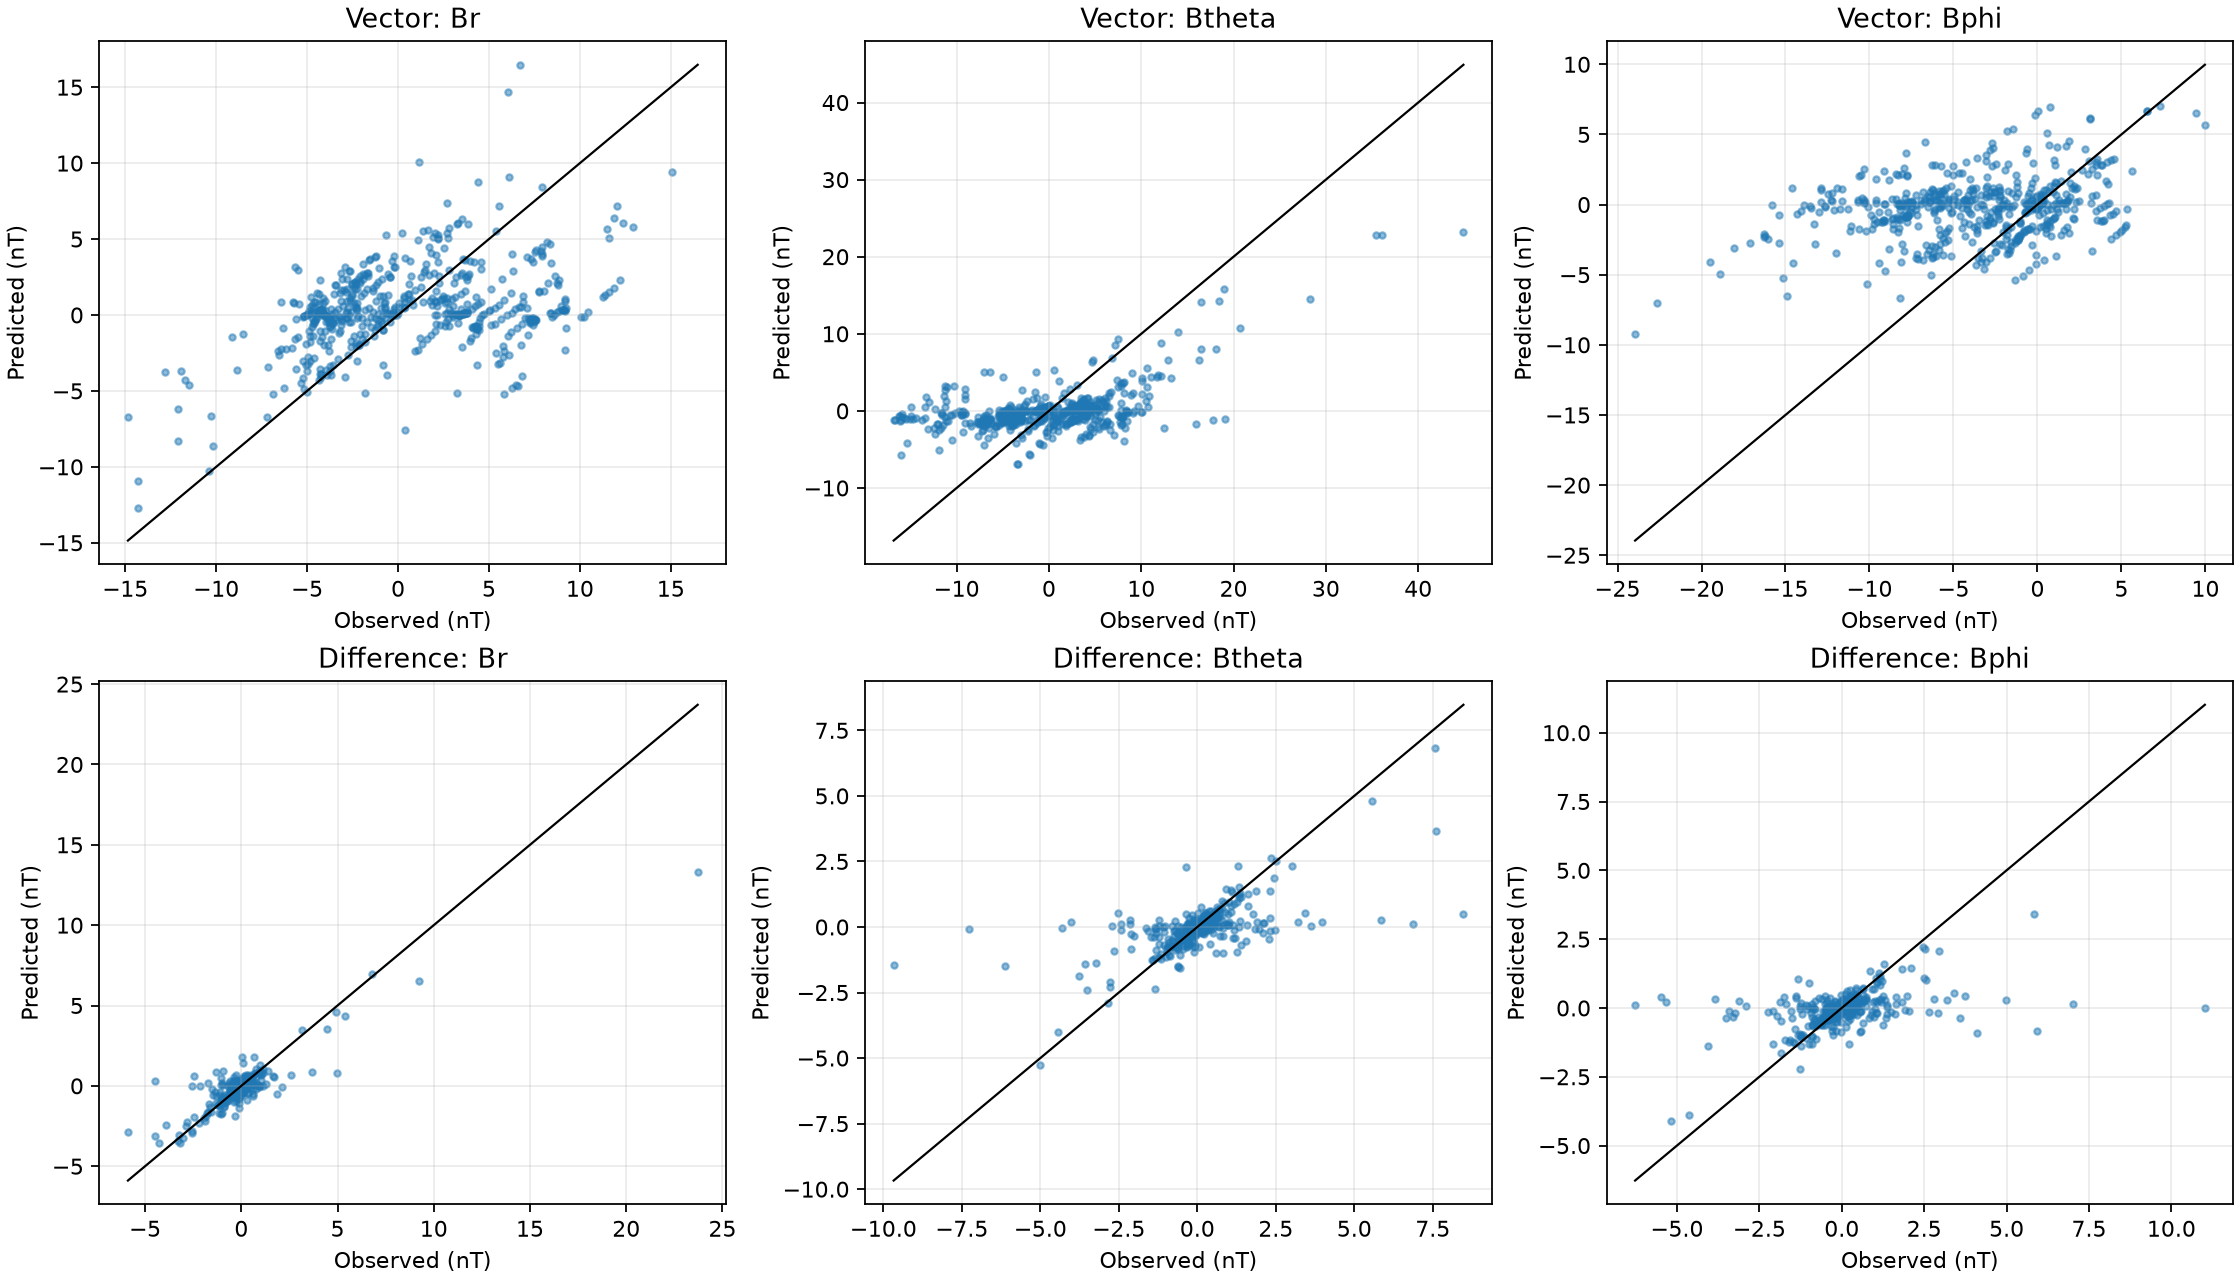

In [8]:
component_rows = []
for kind, observed_values, predicted_values in [
    ('Vector', differences['vector_nt'], fit['predicted_vector_nt']),
    ('Difference', differences['difference_nt'], fit['predicted_difference_nt'])]:
    for j, component in enumerate(['Br','Btheta','Bphi']):
        residual = predicted_values[:,j]-observed_values[:,j]
        component_rows.append(dict(data=kind,component=component,
            bias_nT=np.mean(residual),rmse_nT=np.sqrt(np.mean(residual**2))))
component_metrics = pd.DataFrame(component_rows)
display(component_metrics)
component_metrics.to_csv(OUTPUT/'notebook_component_metrics.csv',index=False)
fig, axes = plt.subplots(2,3,figsize=(14,8),constrained_layout=True)
for row, kind, observed_values, predicted_values in [
    (0,'Vector',differences['vector_nt'],fit['predicted_vector_nt']),
    (1,'Difference',differences['difference_nt'],fit['predicted_difference_nt'])]:
    for j, component in enumerate(['Br','Btheta','Bphi']):
        ax = axes[row,j]
        x,y = observed_values[:,j],predicted_values[:,j]
        ax.scatter(x,y,s=8,alpha=0.5)
        low,high = min(x.min(),y.min()),max(x.max(),y.max())
        ax.plot([low,high],[low,high],color='black',lw=1)
        ax.set(title=f'{kind}: {component}',xlabel='Observed (nT)',ylabel='Predicted (nT)')
        ax.grid(alpha=0.25)
fig.savefig(OUTPUT/'vector_difference_fit.png',dpi=160)
plt.show()
